# Flight log exploration — PINN data prep

Purpose: look at the four sample flight logs before writing any PINN code, and decide
three things.

1. **Which samples are usable** — the logs include pre-arm idle time and rare loop stalls.
2. **How noisy the gyro is** — a physics residual needs d(omega)/dt, and differentiating
   noisy data amplifies that noise.
3. **What the residual can actually be built from** — these logs contain gyro rates, stick
   setpoints and PID term contributions, but **no motor commands, no accelerometer and no
   attitude**, so the input torque is not directly measured.

Source: `software/sample-flight-logs/*.csv`, produced by `download_logs_v4.py` from the
Teensy binary logs (firmware `pid_esc_rx_gyro_v10`, 1 kHz control loop).

In [1]:
# ============================================================
# Imports and configuration
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


# ------------------------------------------------------------
# Locate the log directory (repo-relative, no absolute paths)
# ------------------------------------------------------------

HERE = Path.cwd()

LOG_DIR = (HERE / ".." / "sample-flight-logs").resolve()

if not LOG_DIR.is_dir():
    LOG_DIR = next(
        p for p in [HERE, *HERE.parents]
        if (p / "software" / "sample-flight-logs").is_dir()
    ) / "software" / "sample-flight-logs"

LOG_FILES = sorted(LOG_DIR.glob("logs*.csv"))

LOOP_PERIOD_US = 1000.0   # firmware LOOP_PERIOD_US
FS = 1000.0               # nominal sample rate [Hz]
DT_OUTLIER_US = 2000.0    # a tick longer than this is a stall

print(f"Log directory: {LOG_DIR}")
for f in LOG_FILES:
    print(f"  {f.name}  {f.stat().st_size / 1e6:7.1f} MB")

Log directory: /Users/daniel/Documents/Drone-Project/software/sample-flight-logs
  logs0306.csv     38.3 MB
  logs0311.csv     66.5 MB
  logs0326.csv     92.6 MB
  logs0330.csv     92.8 MB


In [2]:
# ============================================================
# Loader
# ============================================================

# The 9 PID gain columns are constant within a file (they come from the
# binary header and are repeated on every row), so read them once from the
# first data row and skip them for the bulk load.

GAIN_COLS = [
    "roll_coeff_p", "roll_coeff_i", "roll_coeff_d",
    "pitch_coeff_p", "pitch_coeff_i", "pitch_coeff_d",
    "yaw_coeff_p", "yaw_coeff_i", "yaw_coeff_d",
]

SIGNAL_COLS = [
    "time_us", "dt",
    "gyroRoll", "gyroPitch", "gyroYaw",
    "rxThrottle",
    "desiredRollRate", "desiredPitchRate", "desiredYawRate",
    "armSwitch", "frameLost", "failsafe",
    "pRoll", "iRoll", "dRoll",
    "pPitch", "iPitch", "dPitch",
    "pYaw", "iYaw", "dYaw",
]

DTYPES = {c: np.float32 for c in SIGNAL_COLS}
DTYPES["time_us"] = np.int64
for c in ("armSwitch", "frameLost", "failsafe"):
    DTYPES[c] = np.uint8


def load_log(path):
    """Load one flight log. Returns (dataframe, gains dict)."""

    gains = (
        pd.read_csv(path, nrows=1, usecols=GAIN_COLS)
        .iloc[0]
        .to_dict()
    )

    df = pd.read_csv(path, usecols=SIGNAL_COLS, dtype=DTYPES)

    df["t"] = df["time_us"] / 1e6       # seconds since logging start
    df["dt_us"] = df["dt"] * 1e6

    return df, gains


def armed_segments(df):
    """Index ranges where armSwitch is high. Returns list of (start, end)."""

    a = df["armSwitch"].to_numpy().astype(np.int8)
    edges = np.diff(a)

    starts = list(np.where(edges == 1)[0] + 1)
    ends = list(np.where(edges == -1)[0] + 1)

    if a[0] == 1:
        starts.insert(0, 0)
    if a[-1] == 1:
        ends.append(len(a) - 1)

    return list(zip(starts, ends))


logs = {}
gains = {}

for f in LOG_FILES:
    name = f.stem
    logs[name], gains[name] = load_log(f)
    print(f"{name}: {len(logs[name]):,} rows loaded")

NAMES = list(logs)

logs0306: 94,670 rows loaded
logs0311: 158,858 rows loaded
logs0326: 238,676 rows loaded
logs0330: 226,031 rows loaded


## 1. Overview

One row per flight: length, armed time, gains in force, and the flags.

In [3]:
# ============================================================
# Summary table
# ============================================================

rows = []

for name in NAMES:

    df = logs[name]
    g = gains[name]
    segs = armed_segments(df)

    armed_s = sum(
        (df["t"].iloc[e] - df["t"].iloc[s]) for s, e in segs
    )

    rows.append({
        "log": name,
        "rows": len(df),
        "duration_s": round(df["t"].iloc[-1], 1),
        "armed_s": round(armed_s, 1),
        "arms": len(segs),
        "roll_PID": f"{g['roll_coeff_p']:g}/{g['roll_coeff_i']:g}/{g['roll_coeff_d']:g}",
        "pitch_PID": f"{g['pitch_coeff_p']:g}/{g['pitch_coeff_i']:g}/{g['pitch_coeff_d']:g}",
        "yaw_PID": f"{g['yaw_coeff_p']:g}/{g['yaw_coeff_i']:g}/{g['yaw_coeff_d']:g}",
        "thr_max": round(df["rxThrottle"].max(), 3),
        "frameLost": int(df["frameLost"].sum()),
        "failsafe": int(df["failsafe"].sum()),
        "dt>2ms": int((df["dt_us"] > DT_OUTLIER_US).sum()),
        "dt_max_ms": round(df["dt_us"].max() / 1000, 1),
    })

summary = pd.DataFrame(rows).set_index("log")
summary

,rows,duration_s,armed_s,arms,roll_PID,pitch_PID,yaw_PID,thr_max,frameLost,failsafe,dt>2ms,dt_max_ms
log,,,,,,,,,,,,
logs0306,94670,94.7,66.5,1,1.2/4/0.045,1.1/4/0.045,1.4/2.2/0.02,0.336,33,33,17,79.2
logs0311,158858,158.9,122.4,1,1.2/4/0.045,1.1/4/0.045,1.4/2.2/0.02,0.809,0,0,19,51.8
logs0326,238676,238.7,182.4,1,1.1/4/0.03,1.1/4/0.03,1.1/2.2/0,0.301,0,0,31,53.8
logs0330,226031,226.0,191.5,2,1.1/4/0.025,1.1/4/0.025,1.8/2.2/0,0.684,23,23,31,57.7


## 2. Flight timeline

Throttle over time with the armed intervals shaded. This is what the trainer has to
select: everything outside the shaded regions is the quadcopter sitting on the ground
with the motors stopped, and feeding it to a PINN would teach it that zero torque
produces zero rotation — true, but useless, and it would dominate the loss by sample
count.

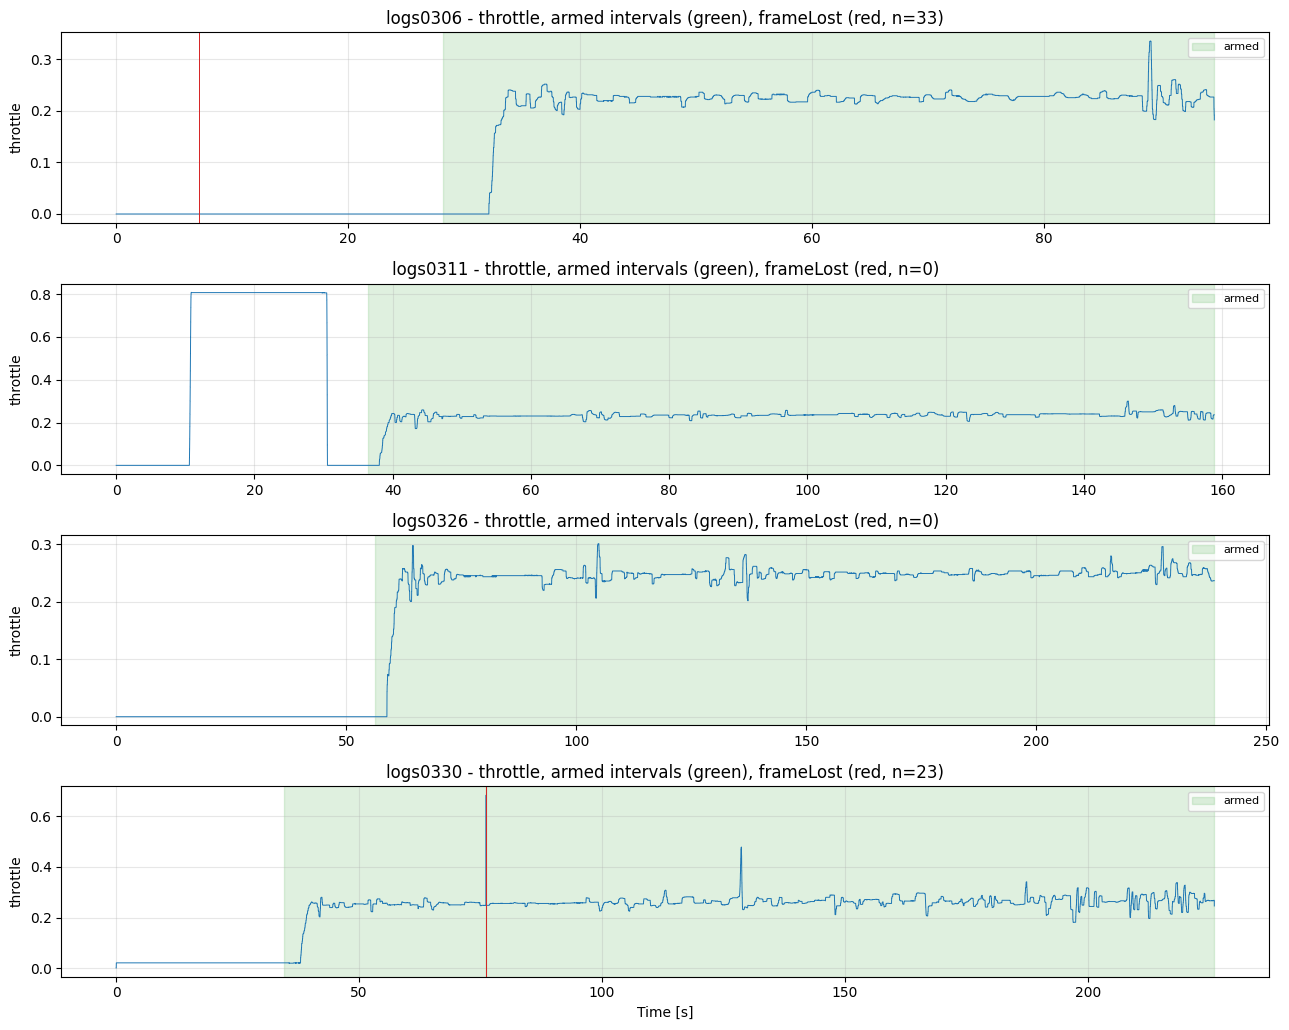

In [4]:
# ============================================================
# Throttle and arm state
# ============================================================

fig, axes = plt.subplots(
    len(NAMES), 1,
    figsize=(13, 2.6 * len(NAMES)),
    sharex=False
)

for ax, name in zip(np.atleast_1d(axes), NAMES):

    df = logs[name]

    ax.plot(df["t"], df["rxThrottle"], lw=0.7, color="tab:blue")

    for n, (s, e) in enumerate(armed_segments(df)):
        ax.axvspan(
            df["t"].iloc[s], df["t"].iloc[e],
            color="tab:green", alpha=0.15,
            label="armed" if n == 0 else None
        )

    # Mark receiver dropouts
    lost = df.loc[df["frameLost"] > 0, "t"]
    for x in lost:
        ax.axvline(x, color="tab:red", lw=0.5, alpha=0.6)

    ax.set_ylabel("throttle")
    ax.set_title(
        f"{name} - throttle, armed intervals (green), "
        f"frameLost (red, n={len(lost)})"
    )
    ax.legend(loc="upper right", fontsize=8)

np.atleast_1d(axes)[-1].set_xlabel("Time [s]")
fig.tight_layout()
plt.show()

## 3. Control loop timing

The firmware targets a fixed 1 kHz tick. The mean `dt` hits that exactly, but the tail
does not: every log has a few dozen ticks beyond 10 ms, worst case ~79 ms. `sum(dt)`
matches the elapsed `time_us`, so no samples are missing — the loop genuinely blocked,
most likely on the SD write inside `loopSD`.

This matters for a PINN twice over: those ticks break the uniform-sampling assumption,
and any finite-difference derivative across them is meaningless.

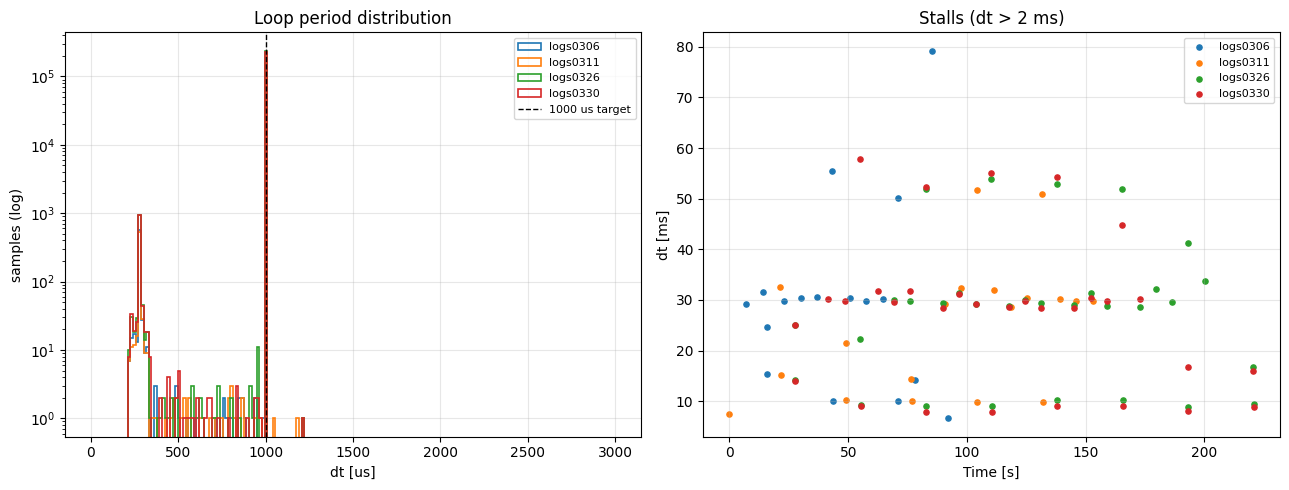

Loop timing per log
------------------------------------------------------------
logs0306: mean= 1000.0 us  std= 457.5  max=  79.2 ms  >2ms= 17  >10ms= 14  (0.018% of samples)
logs0311: mean= 1000.0 us  std= 301.4  max=  51.8 ms  >2ms= 19  >10ms= 16  (0.012% of samples)
logs0326: mean= 1000.0 us  std= 339.6  max=  53.8 ms  >2ms= 31  >10ms= 26  (0.013% of samples)
logs0330: mean= 1000.0 us  std= 353.3  max=  57.7 ms  >2ms= 31  >10ms= 24  (0.014% of samples)


In [5]:
# ============================================================
# dt distribution and stalls
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for name in NAMES:
    ax1.hist(
        logs[name]["dt_us"],
        bins=np.linspace(0, 3000, 200),
        histtype="step", lw=1.2, label=name
    )

ax1.axvline(LOOP_PERIOD_US, color="k", ls="--", lw=1, label="1000 us target")
ax1.set_yscale("log")
ax1.set_xlabel("dt [us]")
ax1.set_ylabel("samples (log)")
ax1.set_title("Loop period distribution")
ax1.legend(fontsize=8)

for name in NAMES:
    df = logs[name]
    m = df["dt_us"] > DT_OUTLIER_US
    ax2.scatter(df.loc[m, "t"], df.loc[m, "dt_us"] / 1000, s=14, label=name)

ax2.set_xlabel("Time [s]")
ax2.set_ylabel("dt [ms]")
ax2.set_title(f"Stalls (dt > {DT_OUTLIER_US/1000:g} ms)")
ax2.legend(fontsize=8)

fig.tight_layout()
plt.show()

print("Loop timing per log")
print("-" * 60)
for name in NAMES:
    d = logs[name]["dt_us"]
    print(
        f"{name}: mean={d.mean():7.1f} us  std={d.std():6.1f}  "
        f"max={d.max()/1000:6.1f} ms  "
        f">2ms={int((d > 2000).sum()):3d}  >10ms={int((d > 10000).sum()):3d}  "
        f"({(d > 2000).mean()*100:.3f}% of samples)"
    )

## 4. Rate tracking

Measured body rate against the stick setpoint, per axis, over the armed portion of each
flight. This is the closed-loop behaviour a PINN would have to reproduce — and the gap
between the two traces is what the controller could not deliver.

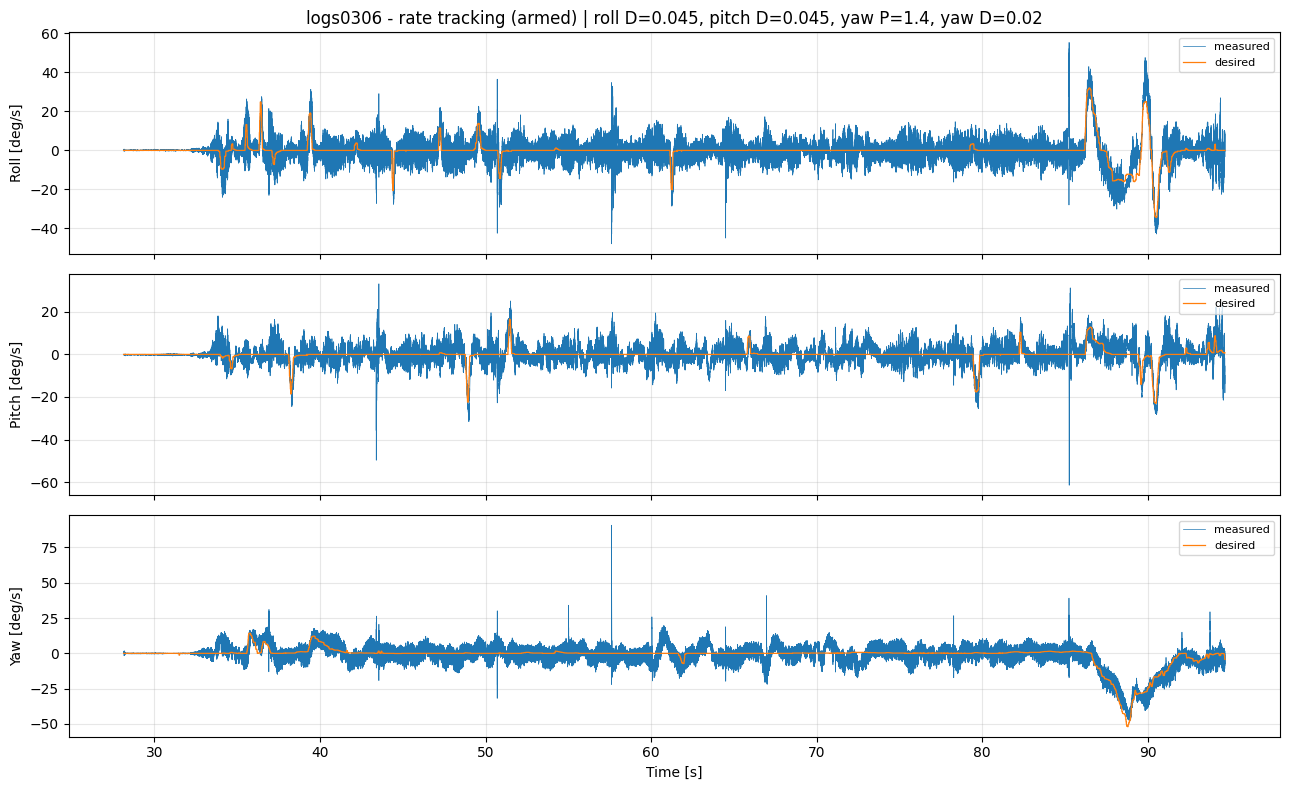

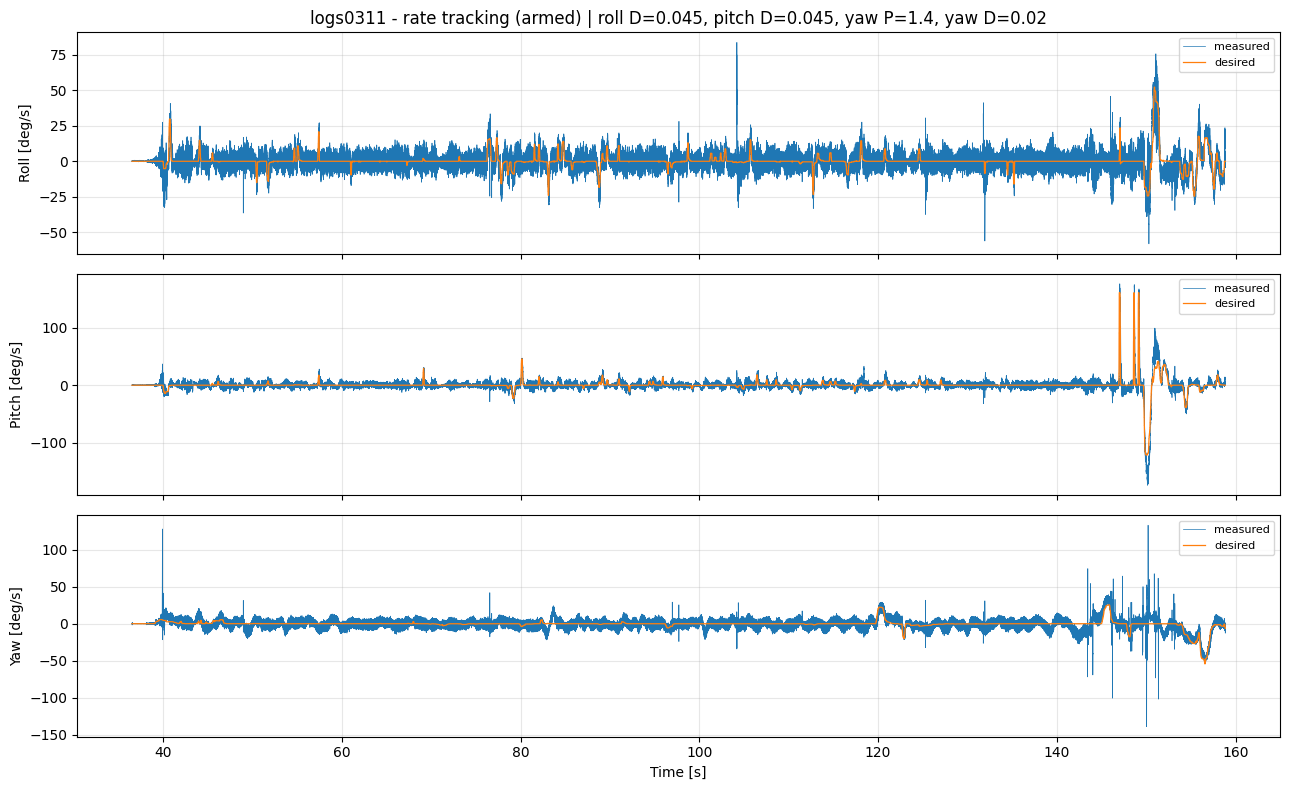

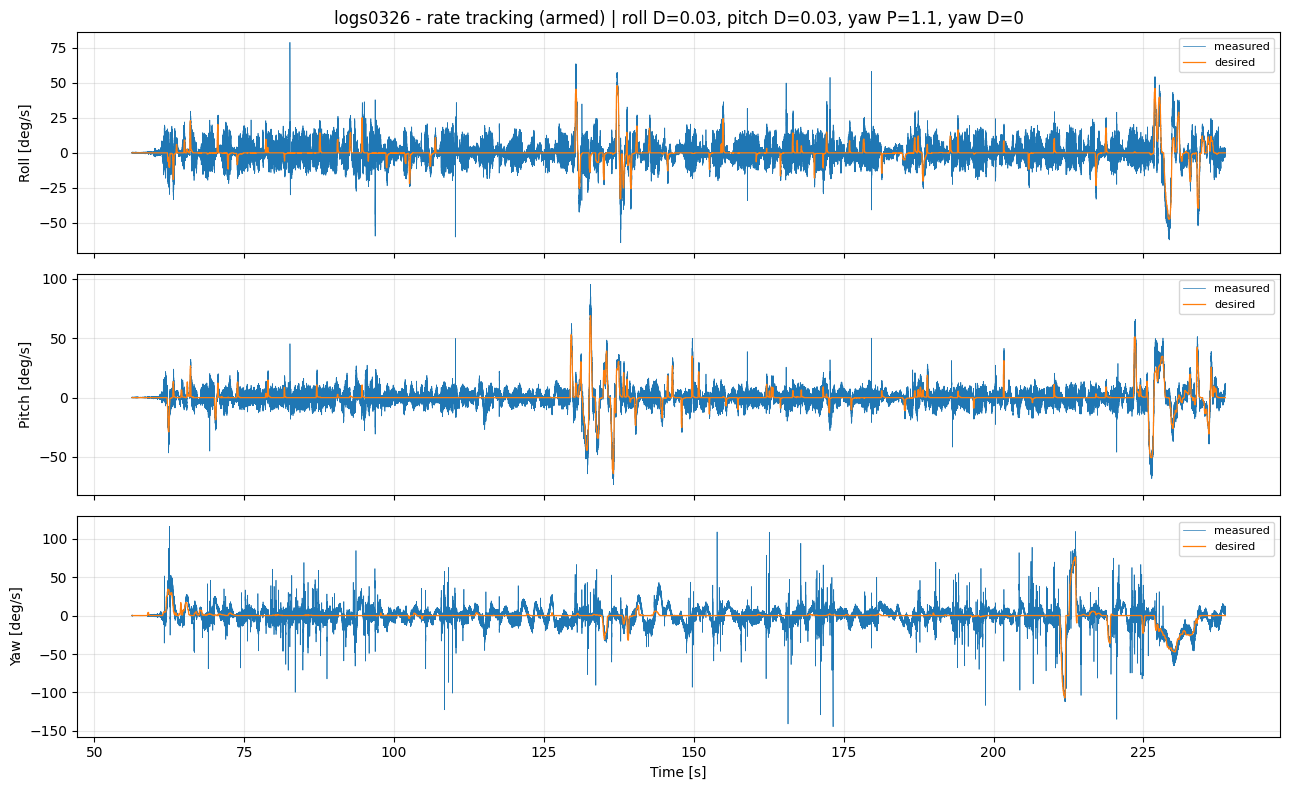

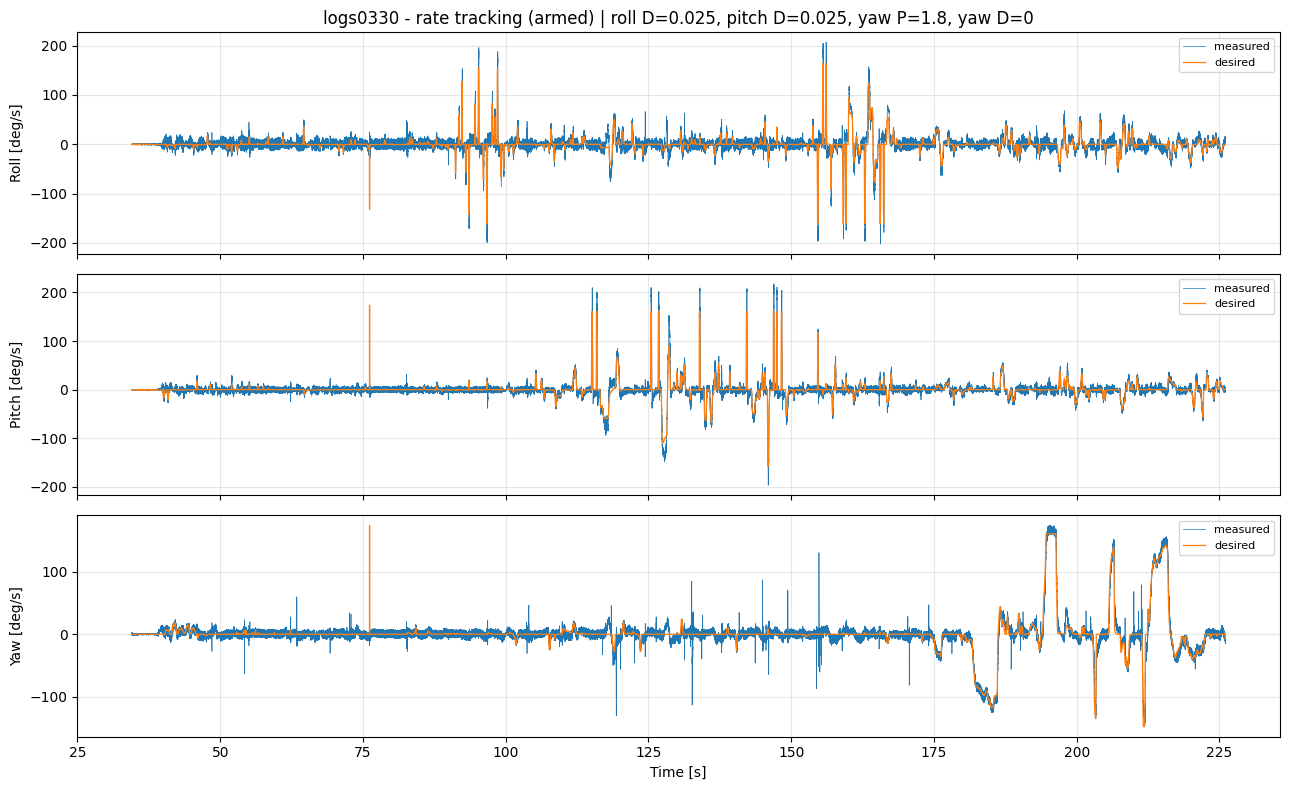

In [6]:
# ============================================================
# Measured vs desired rate, all logs, all axes
# ============================================================

AXES = [
    ("Roll", "gyroRoll", "desiredRollRate"),
    ("Pitch", "gyroPitch", "desiredPitchRate"),
    ("Yaw", "gyroYaw", "desiredYawRate"),
]

for name in NAMES:

    df = logs[name]
    segs = armed_segments(df)
    s, e = segs[0][0], segs[-1][1]
    sl = slice(s, e)

    fig, axs = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

    for ax, (label, meas, want) in zip(axs, AXES):
        ax.plot(df["t"][sl], df[meas][sl], lw=0.5,
                color="tab:blue", label="measured")
        ax.plot(df["t"][sl], df[want][sl], lw=0.9,
                color="tab:orange", label="desired")
        ax.set_ylabel(f"{label} [deg/s]")
        ax.legend(loc="upper right", fontsize=8)

    g = gains[name]
    axs[0].set_title(
        f"{name} - rate tracking (armed) | "
        f"roll D={g['roll_coeff_d']:g}, pitch D={g['pitch_coeff_d']:g}, "
        f"yaw P={g['yaw_coeff_p']:g}, yaw D={g['yaw_coeff_d']:g}"
    )
    axs[-1].set_xlabel("Time [s]")

    fig.tight_layout()
    plt.show()

### 4b. Zoom

The full-flight view above is too dense to judge phase lag or overshoot. A 4-second
window on the most aggressive log shows the actual step response.

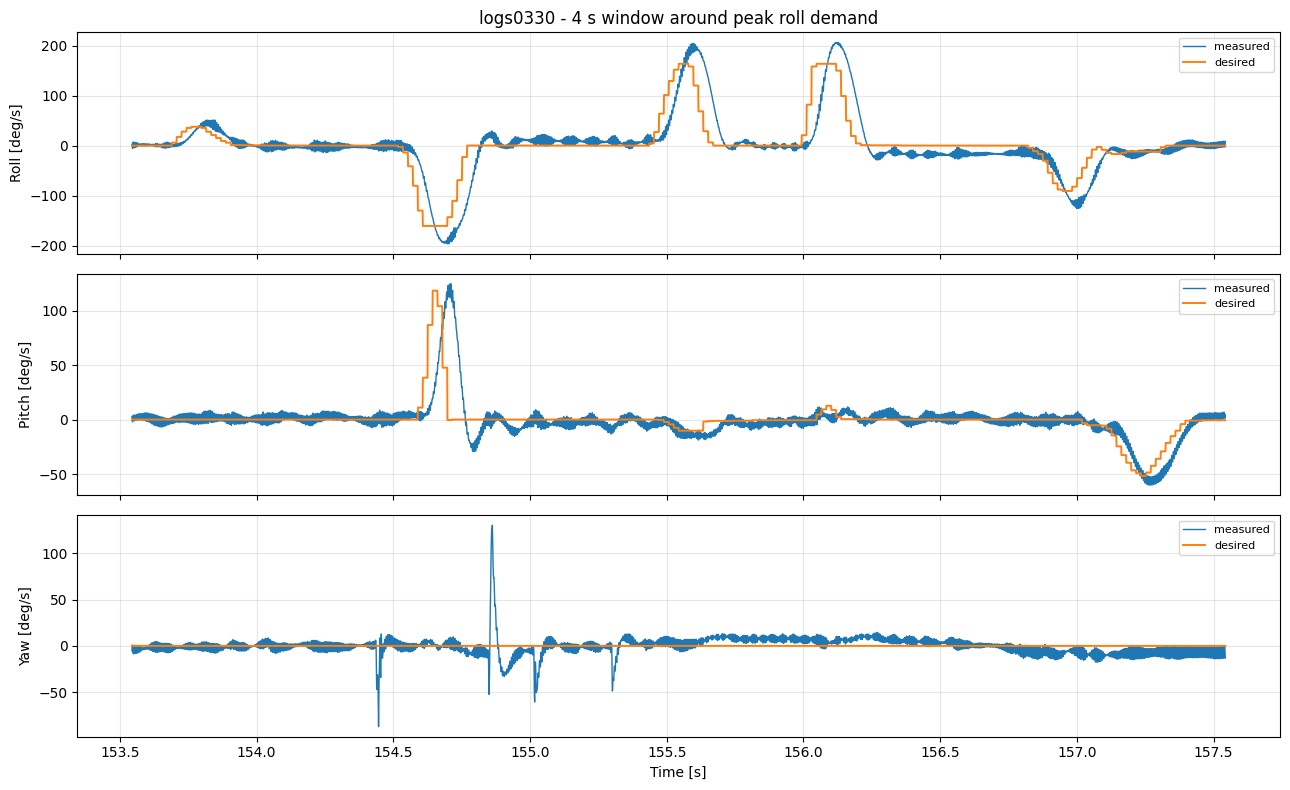

In [7]:
# ============================================================
# 4 s zoom on the largest stick input
# ============================================================

name = max(
    NAMES,
    key=lambda n: logs[n]["desiredRollRate"].abs().max()
)

df = logs[name]

# Centre the window on the biggest roll demand
i = int(df["desiredRollRate"].abs().idxmax())
half = int(2.0 * FS)
sl = slice(max(0, i - half), min(len(df), i + half))

fig, axs = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

for ax, (label, meas, want) in zip(axs, AXES):
    ax.plot(df["t"][sl], df[meas][sl], lw=1.0, label="measured")
    ax.plot(df["t"][sl], df[want][sl], lw=1.4, label="desired")
    ax.set_ylabel(f"{label} [deg/s]")
    ax.legend(loc="upper right", fontsize=8)

axs[0].set_title(f"{name} - 4 s window around peak roll demand")
axs[-1].set_xlabel("Time [s]")

fig.tight_layout()
plt.show()

## 5. Tracking error

Distribution of (desired - measured) per axis, armed samples only. Useful as a baseline:
a PINN that predicts the rate response has to beat these numbers to be worth anything.

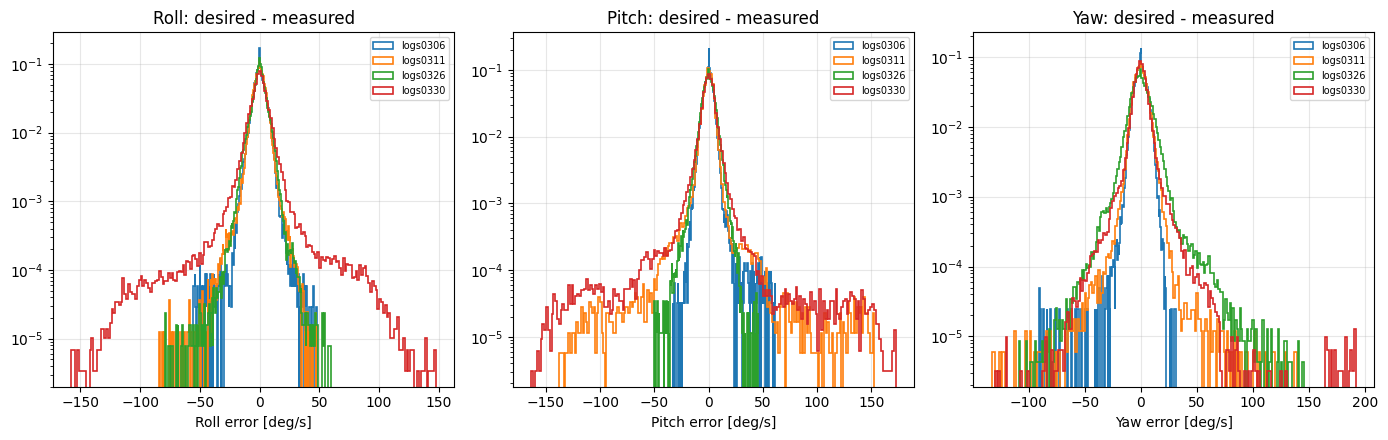

err_rms               err_p95              
axis       Pitch   Roll    Yaw   Pitch   Roll    Yaw
log                                                 
logs0306    4.77   5.36   5.24    8.85  10.58  10.12
logs0311    8.23   5.63   6.48   10.21  10.57  11.56
logs0326    5.69   5.98  10.05   11.28  12.35  18.82
logs0330   11.66  12.02   7.67   15.18  18.91  13.51

In [8]:
# ============================================================
# Error distributions and RMS
# ============================================================

fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))

err_rows = []

for ax, (label, meas, want) in zip(axs, AXES):

    for name in NAMES:
        df = logs[name]
        segs = armed_segments(df)
        sl = slice(segs[0][0], segs[-1][1])

        err = (df[want][sl] - df[meas][sl]).to_numpy()

        ax.hist(err, bins=200, histtype="step", lw=1.2,
                density=True, label=name)

        err_rows.append({
            "log": name,
            "axis": label,
            "err_rms": np.sqrt(np.mean(err ** 2)),
            "err_p95": np.percentile(np.abs(err), 95),
            "meas_rms": np.sqrt(np.mean(df[meas][sl].to_numpy() ** 2)),
        })

    ax.set_xlabel(f"{label} error [deg/s]")
    ax.set_yscale("log")
    ax.set_title(f"{label}: desired - measured")
    ax.legend(fontsize=7)

fig.tight_layout()
plt.show()

err_df = pd.DataFrame(err_rows).pivot(
    index="log", columns="axis",
    values=["err_rms", "err_p95"]
).round(2)

err_df

## 6. PID term contributions

What the controller was doing internally. These are the only actuation-side signals in
the log — note that they are *controller output terms*, not motor commands: the sum
`p + i + d` per axis goes through `motor_mix.h` before reaching the ESCs, and the mixer
output is not logged.

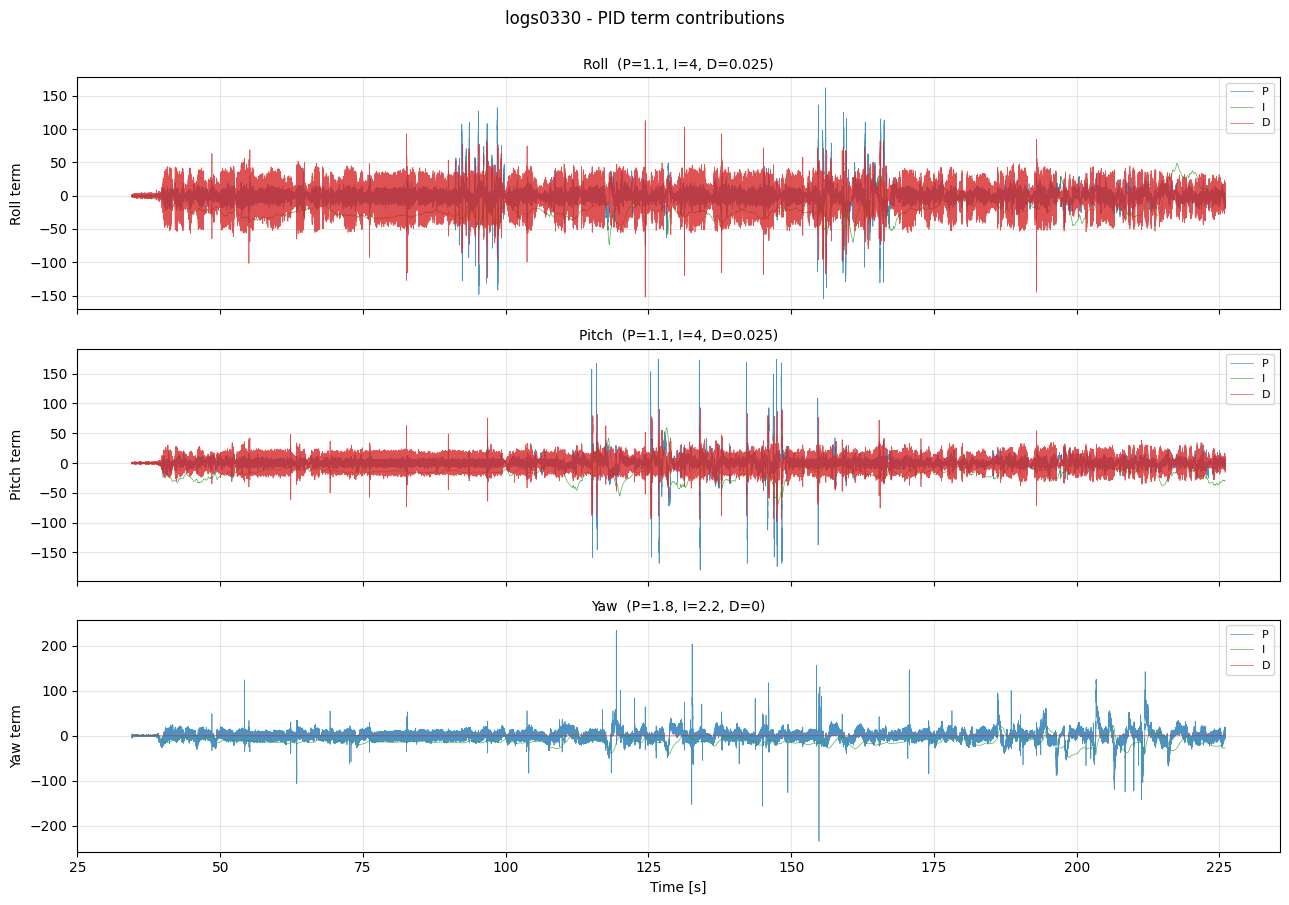

In [9]:
# ============================================================
# P, I, D terms per axis
# ============================================================

name = NAMES[-1]
df = logs[name]
segs = armed_segments(df)
sl = slice(segs[0][0], segs[-1][1])

fig, axs = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

for ax, axis in zip(axs, ["Roll", "Pitch", "Yaw"]):

    for term, color in zip("pid", ["tab:blue", "tab:green", "tab:red"]):
        ax.plot(
            df["t"][sl], df[term + axis][sl],
            lw=0.5, color=color, alpha=0.8,
            label=term.upper()
        )

    g = gains[name]
    k = axis.lower()
    ax.set_ylabel(f"{axis} term")
    ax.set_title(
        f"{axis}  (P={g[k+'_coeff_p']:g}, "
        f"I={g[k+'_coeff_i']:g}, D={g[k+'_coeff_d']:g})",
        fontsize=10
    )
    ax.legend(loc="upper right", fontsize=8)

axs[0].figure.suptitle(f"{name} - PID term contributions", y=1.0)
axs[-1].set_xlabel("Time [s]")

fig.tight_layout()
plt.show()

## 7. Gyro noise spectrum

Welch PSD of the measured rates over the armed portion, at 1 kHz. This is the single most
important plot for deciding whether a physics residual is viable: the propeller
fundamental and its harmonics sit on top of the rigid-body motion, and differentiation
multiplies amplitude by frequency, so high-frequency vibration dominates d(omega)/dt
unless it is filtered or the residual is formulated in integral form.

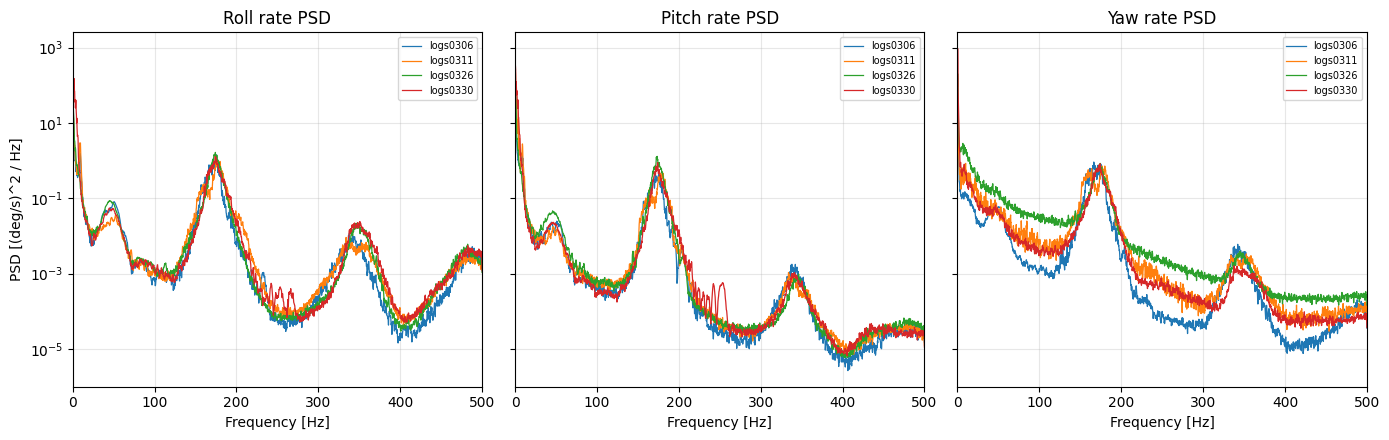

Dominant vibration peaks above 20 Hz
------------------------------------------------------------
logs0306: Roll= 175.0 Hz   Pitch= 171.1 Hz   Yaw= 166.5 Hz   
logs0311: Roll= 176.8 Hz   Pitch= 179.9 Hz   Yaw= 176.8 Hz   
logs0326: Roll= 174.3 Hz   Pitch= 173.6 Hz   Yaw= 174.3 Hz   
logs0330: Roll= 174.3 Hz   Pitch= 174.1 Hz   Yaw= 174.1 Hz   


In [10]:
# ============================================================
# Power spectral density of gyro signals
# ============================================================

fig, axs = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)

for ax, (label, meas, _) in zip(axs, AXES):

    for name in NAMES:
        df = logs[name]
        segs = armed_segments(df)
        sl = slice(segs[0][0], segs[-1][1])

        x = df[meas][sl].to_numpy(dtype=np.float64)
        x = x - x.mean()

        f, pxx = signal.welch(x, fs=FS, nperseg=4096)

        ax.semilogy(f, pxx, lw=0.9, label=name)

    ax.set_xlabel("Frequency [Hz]")
    ax.set_xlim(0, FS / 2)
    ax.set_title(f"{label} rate PSD")
    ax.legend(fontsize=7)

axs[0].set_ylabel("PSD [(deg/s)^2 / Hz]")

fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# Dominant spectral lines (above 20 Hz, i.e. not rigid-body motion)
# ------------------------------------------------------------

print("Dominant vibration peaks above 20 Hz")
print("-" * 60)

for name in NAMES:
    df = logs[name]
    segs = armed_segments(df)
    sl = slice(segs[0][0], segs[-1][1])

    line = f"{name}: "

    for label, meas, _ in AXES:
        x = df[meas][sl].to_numpy(dtype=np.float64)
        f, pxx = signal.welch(x - x.mean(), fs=FS, nperseg=4096)

        band = f > 20
        peak_f = f[band][np.argmax(pxx[band])]

        line += f"{label}={peak_f:6.1f} Hz   "

    print(line)

## 8. Angular acceleration — the PINN problem in one plot

A rigid-body residual needs d(omega)/dt. The log gives omega at 1 kHz, so the derivative
has to be numerical, and that is where the noise from the previous plot shows up. Raw
finite differences against a Savitzky-Golay estimate on the same window:

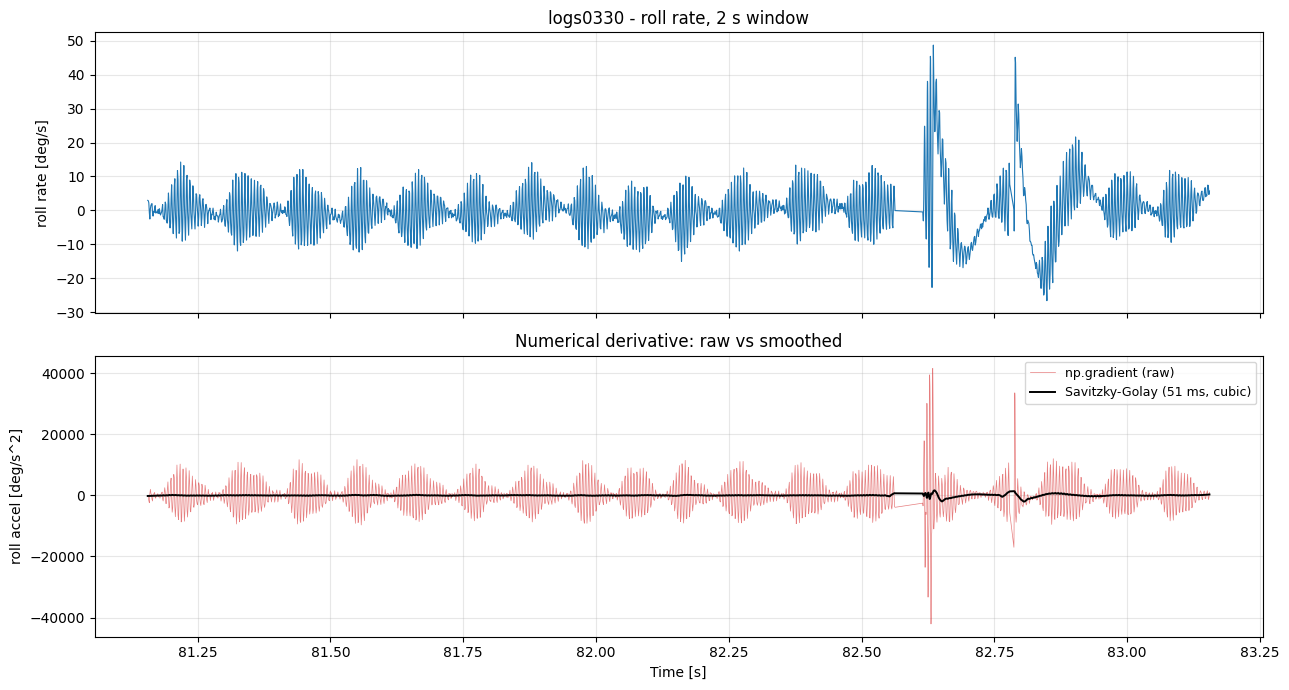

raw  d(omega)/dt: rms=    6090.3 deg/s^2, peak=   42085.5
S-G  d(omega)/dt: rms=     316.1 deg/s^2, peak=    2019.4
noise amplification factor (rms): 19.3x


In [11]:
# ============================================================
# d(omega)/dt: raw finite difference vs smoothed
# ============================================================

name = NAMES[-1]
df = logs[name]

segs = armed_segments(df)
i0 = segs[-1][0] + int(5 * FS)
sl = slice(i0, i0 + int(2.0 * FS))      # 2 s window, well inside a flight

t = df["t"][sl].to_numpy(dtype=np.float64)
w = df["gyroRoll"][sl].to_numpy(dtype=np.float64)

# Raw non-uniform finite difference
dw_raw = np.gradient(w, t)

# Savitzky-Golay derivative (51-sample window = 51 ms, cubic)
dw_sg = signal.savgol_filter(
    w, window_length=51, polyorder=3,
    deriv=1, delta=1.0 / FS
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

ax1.plot(t, w, lw=0.8, color="tab:blue")
ax1.set_ylabel("roll rate [deg/s]")
ax1.set_title(f"{name} - roll rate, 2 s window")

ax2.plot(t, dw_raw, lw=0.5, color="tab:red", alpha=0.6,
         label="np.gradient (raw)")
ax2.plot(t, dw_sg, lw=1.4, color="k",
         label="Savitzky-Golay (51 ms, cubic)")
ax2.set_ylabel("roll accel [deg/s^2]")
ax2.set_xlabel("Time [s]")
ax2.set_title("Numerical derivative: raw vs smoothed")
ax2.legend(fontsize=9)

fig.tight_layout()
plt.show()

print(f"raw  d(omega)/dt: rms={np.sqrt(np.mean(dw_raw**2)):10.1f} deg/s^2, "
      f"peak={np.abs(dw_raw).max():10.1f}")
print(f"S-G  d(omega)/dt: rms={np.sqrt(np.mean(dw_sg**2)):10.1f} deg/s^2, "
      f"peak={np.abs(dw_sg).max():10.1f}")
print(f"noise amplification factor (rms): "
      f"{np.sqrt(np.mean(dw_raw**2)) / np.sqrt(np.mean(dw_sg**2)):.1f}x")

## 9. Cross-flight comparison

The four logs are a tuning sweep: roll/pitch D steps down 0.045 -> 0.03 -> 0.025, and yaw
D is zeroed on the last two while yaw P is raised. Tracking error against the gains that
produced it.

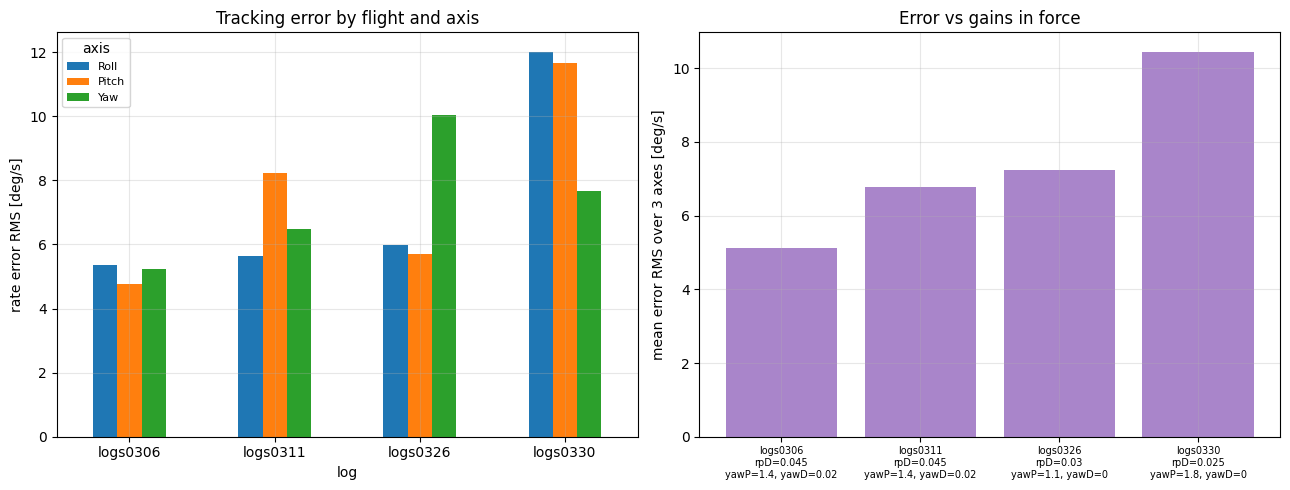

axis,Roll,Pitch,Yaw
log,,,
logs0306,5.36,4.77,5.24
logs0311,5.63,8.23,6.48
logs0326,5.98,5.69,10.05
logs0330,12.02,11.66,7.67


In [12]:
# ============================================================
# Error vs gains across the four flights
# ============================================================

comp = pd.DataFrame(err_rows).pivot(
    index="log", columns="axis", values="err_rms"
)[["Roll", "Pitch", "Yaw"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

comp.plot(kind="bar", ax=ax1, rot=0)
ax1.set_ylabel("rate error RMS [deg/s]")
ax1.set_title("Tracking error by flight and axis")
ax1.legend(title="axis", fontsize=8)

labels = []
for name in NAMES:
    g = gains[name]
    labels.append(
        f"{name}\nrpD={g['roll_coeff_d']:g}\n"
        f"yawP={g['yaw_coeff_p']:g}, yawD={g['yaw_coeff_d']:g}"
    )

ax2.bar(range(len(NAMES)),
        [comp.loc[n].mean() for n in NAMES],
        color="tab:purple", alpha=0.8)
ax2.set_xticks(range(len(NAMES)))
ax2.set_xticklabels(labels, fontsize=7)
ax2.set_ylabel("mean error RMS over 3 axes [deg/s]")
ax2.set_title("Error vs gains in force")

fig.tight_layout()
plt.show()

comp.round(2)

## Findings

**Usable samples.** Armed intervals only — roughly 66-192 s per flight, about 80% of the
rows. `logs0330` has two separate arms and must be split, not treated as one trajectory.

**Loop stalls.** Each log has a few dozen ticks over 10 ms (worst ~79 ms). They are rare
(~0.014% of samples) but they break any uniform-grid assumption. Either drop a window
around each one or carry the true per-sample `dt` through the model; do not assume 1 ms.

**Gyro noise dominates the derivative.** The PSD shows a strong propeller line near
175 Hz with a harmonic near 345 Hz, well inside the 500 Hz Nyquist band, sitting on top of
rigid-body motion that lives below ~20 Hz. In the 2 s window above, the raw derivative has
an RMS roughly 19x the smoothed estimate and swings +/-20000 deg/s^2 of pure vibration
while the real dynamics are on the order of +/-1000. A collocation residual built on raw
`np.gradient` output would fit propeller vibration, not dynamics. Either low-pass well
below 175 Hz before differentiating, or write the residual in integral form so that no
numerical derivative is needed.

**Missing the actuation side.** No motor commands, no accelerometer, no attitude estimate,
no battery voltage. The PID terms are controller internals upstream of `motor_mix.h`, so
the input torque is not measured and would have to be reconstructed through the mixer plus
an unknown thrust curve — an unidentifiable parameter sitting inside the physics loss. The
cleanest fix is on the firmware side: log the four motor outputs.

**Next:** factor the loader, armed-segment extraction and stall handling in this notebook
into `data.py`, and keep the training loop in `train_pinn.py`.